# Phase I. Foundations of discrete optimal transport

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")
from otlib.discrete import *
from otlib.utils import *

## 1.1 Kantorovich problem as a linear program and duality

### Simple 1D case

Optimal plan:
 [[0.25 0.   0.   0.  ]
 [0.05 0.1  0.   0.  ]
 [0.   0.   0.15 0.  ]
 [0.   0.05 0.2  0.2 ]]
Cost: 0.35


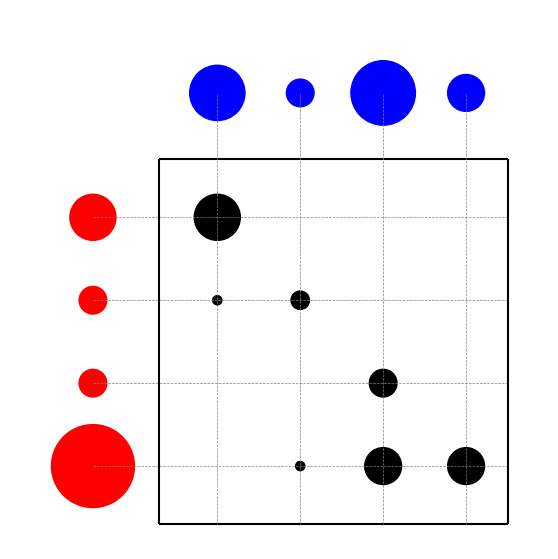

Sparsity of the extremal solution
n+m-1= 7
Number of nonzero entries of P1: 7


In [2]:
C1 = np.array([[0, 1, 2, 3],
              [1, 0, 1, 2],
              [2, 1, 0, 1],
              [3, 2, 1, 0]], dtype=float)
a1 = np.array([0.25, 0.15, 0.15, 0.45], dtype=float)
b1 = np.array([0.3, 0.15, 0.35, 0.2], dtype=float)

P1, obj1p = otdiscrete_primal(a1,b1,C1)
print("Optimal plan:\n",P1)
print("Cost:", obj1p)

plot_1D_transport(a1,[0,1,2,3],b1,[0,1,2,3], P1)

print("Sparsity of the extremal solution")
print("n+m-1=",7)
print("Number of nonzero entries of P1:", np.count_nonzero(P1))


Another optimal plan

Cost of P2: 0.35


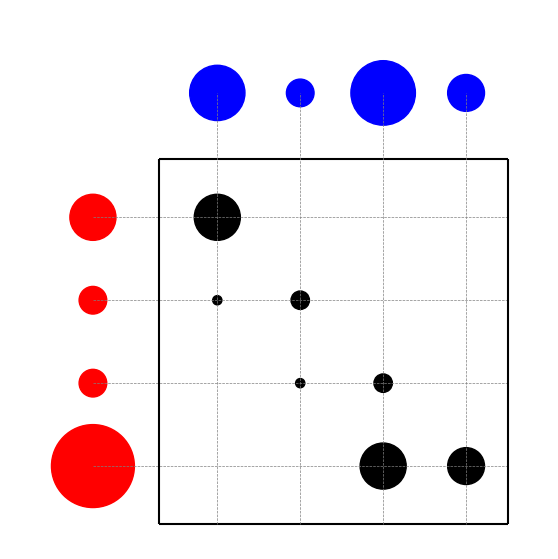

In [3]:
P_o = np.array([
    [0.25,    0,   0,   0],
    [0.05, 0.10,   0,   0],
    [   0, 0.05, 0.10,   0],
    [   0,    0, 0.25, 0.2]
])
print("Cost of P2:", np.sum(P_o*C1))
plot_1D_transport(a1,[0,1,2,3],b1,[0,1,2,3], P_o)

Check the strong duality

In [4]:
f1,g1,obj1d = otdiscrete_dual(a1,b1,C1)
print("Price of f,g:", f"{obj1d:.4g}")

Price of f,g: 0.35


Check for the complementarity slackness

In [5]:
print(P1*(C1 - np.add.outer(f1, g1)))

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


#### 2D exmaples

In [6]:
from tests.cloud_gen import dirichlet_cloud_gen

Small example n=24, m=18

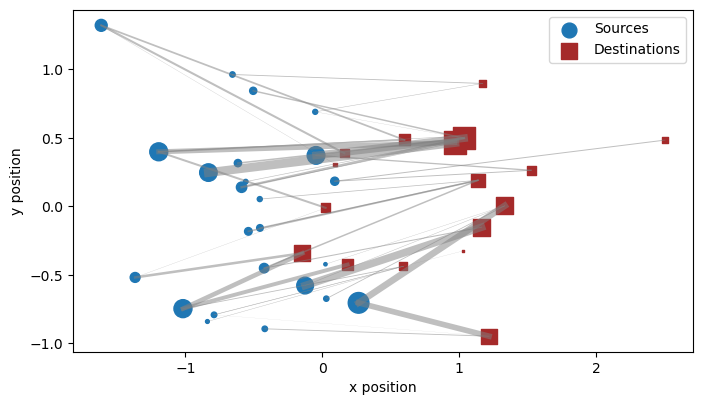

In [7]:
n = 24
m = 18
a2, s2, b2, d2, C2 = dirichlet_cloud_gen(n,m)
P2, obj2p = otdiscrete_primal(a2,b2,C2)

plot_2D_transport(a2,s2,b2,d2, P2)

Extremal solution

In [8]:
print("n+m-1=",n+m-1)
print("Number of nonzero entries of P2:", np.count_nonzero(P2))

n+m-1= 41
Number of nonzero entries of P2: 41


Strong duality

In [9]:
f2,g2, obj2d = otdiscrete_dual(a2,b2,C2)
print("Primal optimal value:",obj2p)
print("Dual optimal value:", obj2d)

Primal optimal value: 2.3766879368891045
Dual optimal value: 2.376687936889104


Complementary slackness

In [10]:
print(n*m-np.sum(np.isclose(P2*(C2 - np.add.outer(f2, g2)),0)))

0


Largest example

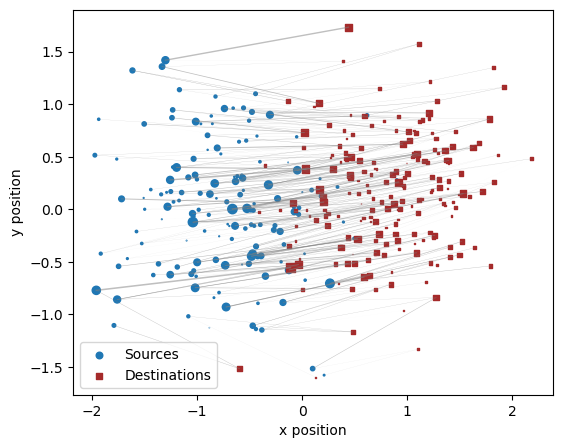

In [11]:
n = 150
m = 200
a3, s3, b3, d3, C3 = dirichlet_cloud_gen(n,m)
P3, obj3p = otdiscrete_primal(a3,b3,C3)
plot_2D_transport(a3,s3,b3,d3, P3)

Extremal solution

In [12]:
print("n+m-1=",n+m-1)
print("Number of nonzero entries of P2:", np.count_nonzero(P3))

n+m-1= 349
Number of nonzero entries of P2: 349


Strong duality

In [13]:
f3,g3, obj3d = otdiscrete_dual(a3,b3,C3)
print("Primal optimal value:",obj3p)
print("Dual optimal value:", obj3d)

Primal optimal value: 2.410104943796241
Dual optimal value: 2.410104943796239


Complementarity slackness

In [14]:
print(n*m-np.sum(np.isclose(P3*(C3 - np.add.outer(f3, g3)),0)))

0


#### Birkhoff's theorem

In [15]:
from tests.cloud_gen import uniform_cloud_gen

Simple example

Cost of the permutation matrix 1.0


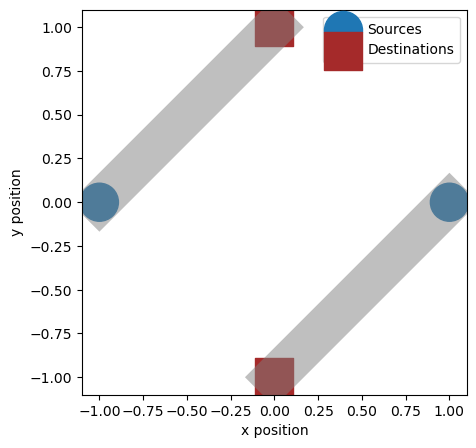

In [16]:
a4 = np.array([0.5,0.5])
s4 = np.array([[1,0],[-1,0]])
d4 = np.array([[0,1],[0,-1]])
C4 = np.array([[1,1],
               [1,1]])
P4, obj4p = otdiscrete_primal(a4,a4, C4)
print("Cost of the permutation matrix",obj4p)
plot_2D_transport(a4,s4,a4,d4,P4)

Not a permutation matrix which is optimal

Cost of this transportation plan: 1.0


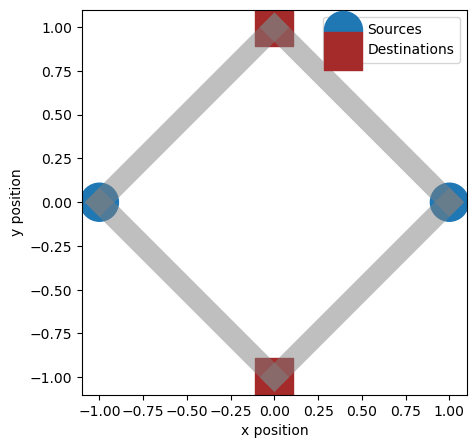

In [17]:
P4_m = np.array([[0.25,0.25],[0.25,0.25]])
print("Cost of this transportation plan:",np.sum(P4_m*C4))
plot_2D_transport(a4,s4,a4,d4,P4_m)

2D example

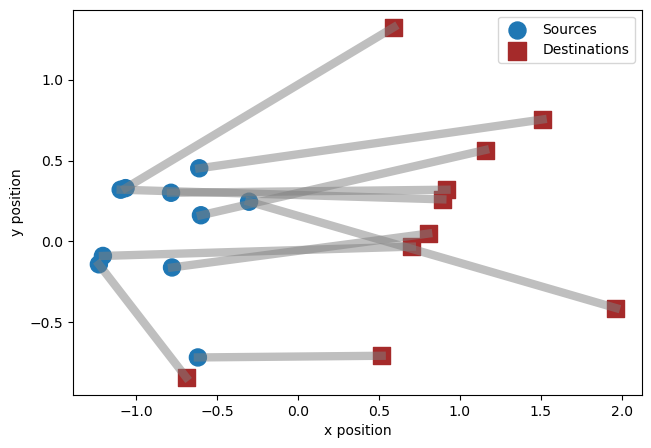

In [18]:
n = 10
a5, s5, b5, d5, C5 = uniform_cloud_gen(n,n)
P5, obj5p = otdiscrete_primal(a5,b5,C5)
plot_2D_transport(a5,s5,b5,d5,P5)

We observed that P5 is a monge map

## The one-dimensional case

In [19]:
from tests.gaussian_gen import gaussian_gen

Test: a = $\mathcal{N}(0, 1)$, b = $\mathcal{N}(5, 1)$

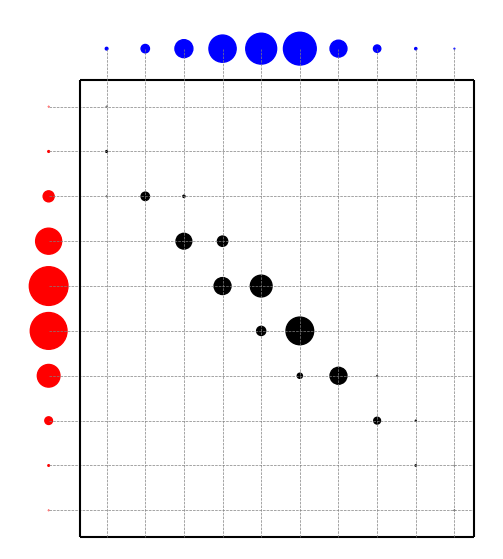

Computation of the 2-Wassertein distance between two gaussian using
Objectif of the LP: 4.869
Close formula: 5.0
Using the quantile funtion: 4.974


In [ ]:
a6,x6,b6,y6,C6 = gaussian_gen(0,1,5,1, n=10)
P6, obj6p = otdiscrete_primal(a6,b6,C6)

plot_1D_transport(a6,x6,b6,y6,P6)

print("Computation of the 2-Wassertein distance between two gaussian using" )
print(f"Objectif of the LP: {np.sqrt(obj6p):.4g}")
print("Close formula:", Gaussian_W2(0,1,5,1))
print(f"The quantile funtion: {Wp_discrete(a6,x6,b6,y6,2):.4g}")

We observe that all values are closed

Test: a = $\mathcal{N}(0, 1)$, b = $\mathcal{N}(0, 10)$

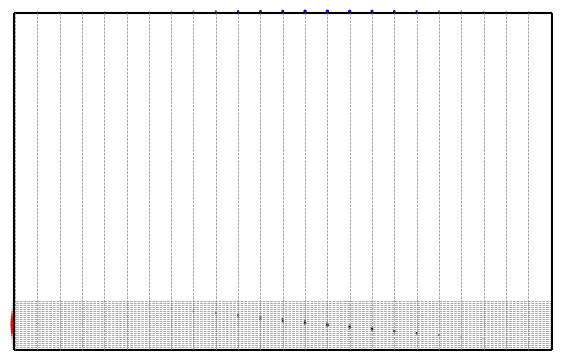

Computation of the 2-Wassertein distance between two gaussian using
Objectif of the LP: 9.066
Close formula: 9.0
The quantile funtion: 9.154


In [29]:
a7,x7,b7,y7,C7 = gaussian_gen(0,1,0,10, N=5000, n=25)
P7, obj7p = otdiscrete_primal(a7,b7,C7)

plot_1D_transport(a7,x7,b7,y7,P7)

print("Computation of the 2-Wassertein distance between two gaussian using" )
print(f"Objectif of the LP: {np.sqrt(obj7p):.4g}")
print("Close formula:", Gaussian_W2(0,1,0,10))
print(f"The quantile funtion: {Wp_discrete(a7,x7,b7,y7,2):.4g}")

Test: a = $\mathcal{N}(-1, 1)$, b = $\mathcal{N}(1, 2)$

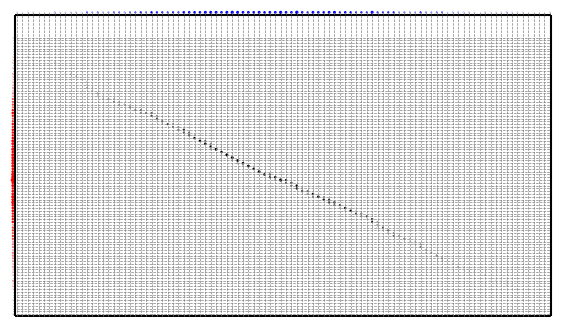

Computation of the 2-Wassertein distance between two gaussian using
Objectif of the LP: 2.272
Close formula: 2.236
The quantile funtion: 2.35


In [32]:
a8,x8,b8,y8,C8 = gaussian_gen(-1,1,1,2)
P8, obj8p = otdiscrete_primal(a8,b8,C8)

plot_1D_transport(a8,x8,b8,y8,P8)

print("Computation of the 2-Wassertein distance between two gaussian using" )
print(f"Objectif of the LP: {np.sqrt(obj8p):.4g}")
print(f"Close formula: {Gaussian_W2(-1,1,1,2):.4g}")
print(f"The quantile funtion: {Wp_discrete(a8,x8,b8,y8,2):.4g}")